In [21]:
pip install opencv-python

Note: you may need to restart the kernel to use updated packages.


In [22]:
import cv2

In [23]:
print(cv2.__version__)

5.0.0


In [24]:
import os
import csv
import numpy as np
import cv2
import matplotlib.pyplot as plt

%matplotlib inline  
#for plotting everything below the cell 

In [49]:
#defining no. of material layers, range of pixels

IMG_W, IMG_H = 384, 256 #IMAGE DIMENSIONS
N_CLASSES = 5       #BACKGROUND, METAL, DIELECTRIC, GATE, SILICON

#RANGE FOR RANDOMIZING EACH GENERATED IMAGE (THESE ARE GROUND TRUTH CDS), all are in px
GATE_WIDTH_RANGE = (30,55) 
GATE_PITCH_EXTRA_RANGE = (35, 70)
GATE_HEIGHT_RANGE = (18,30)
DIELECTRIC_THICKNESS_RANGE = (6,14)
METAL_TOP_ROW_RANGE = (30,55)
CORNER_BLUR_SIGMA_RANGE = (2.0, 5.0)   # randomized per image the corner bending

rng = np.random.default_rng(42) 

In [30]:
# creating the mask layer

def make_layered_pattern(rng, gate_width, gate_pitch, gate_height, dielectric_thickness, metal_top_row):
    """Builds a layered device cross-section mask, column by column:
      silicon (flat) -> gate fingers (periodic bumps) -> dielectric
      (conformal, follows gate/silicon surface) -> metal (fills up to a
      flat top row) -> background above that.

    Label mapping: 0=background, 1=metal, 2=dielectric, 3=gate, 4=silicon
    """

    mask = np.zeros((IMG_H, IMG_W), dtype=np.uint8)
    si_top = IMG_H - 100  #flat si surface from where we will start building features

    mask[si_top:,:] = 4 #si substarte fill everything below si top

    gate_phase = rng.integers(0, gate_pitch) # random horizontal offset

    for col in range(IMG_W):
        is_gate = ((col+gate_phase) % gate_pitch)< gate_width
        local_top = si_top
        if is_gate:
            local_top = si_top - gate_height
            mask[local_top:si_top, col] =3 #gate

        dielectric_top_local = local_top - dielectric_thickness
        mask[dielectric_top_local:local_top, col] = 2 #dielectric

        mask[metal_top_row:dielectric_top_local, col] =1 #metal fills the rest up to flat top
        #rows above metal_top_row stay 0 (background)

    return mask

    
    

In [32]:
import inspect
print(inspect.signature(make_layered_pattern))

(rng, gate_width, gate_pitch, gate_height, dielectric_thickness, metal_top_row)


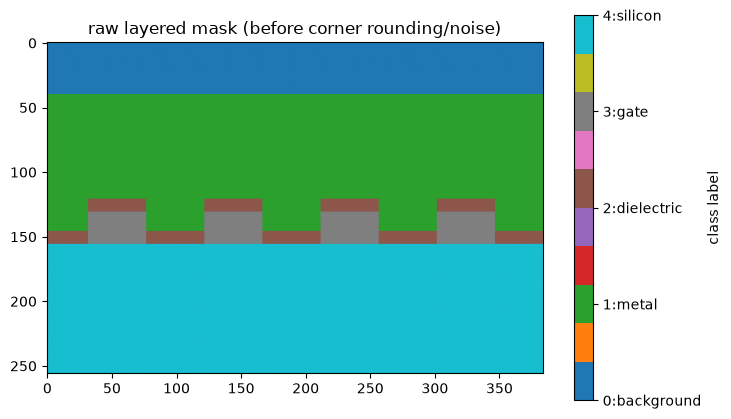

In [33]:
# seeing some images

test_mask = make_layered_pattern(
    rng, gate_width=45, gate_pitch=90, gate_height=25, dielectric_thickness=10, metal_top_row=40)

plt.figure(figsize=(8,5))
im=plt.imshow(test_mask, cmap='tab10', vmin=0, vmax=N_CLASSES-1)
#plt.imshow(test_mask, cmap='tab10', vmin=0, vmax=N_CLASSES-1)
plt.title("raw layered mask (before corner rounding/noise)")

cbar = plt.colorbar(im, ticks=range(N_CLASSES))
cbar.set_label("class label")
cbar.ax.set_yticklabels(['0:background', '1:metal', '2:dielectric', '3:gate', '4:silicon'])

plt.show()


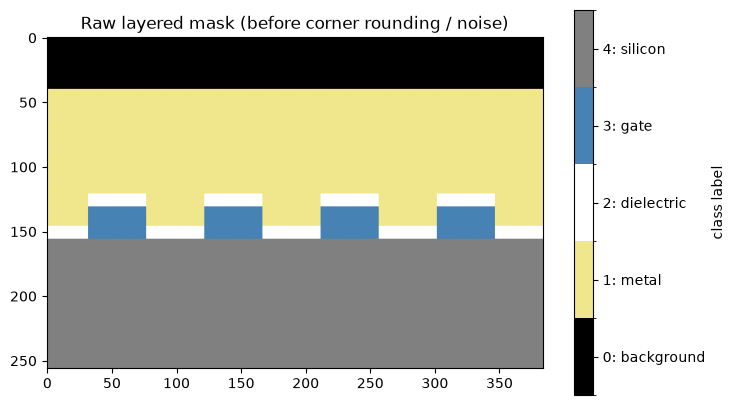

In [35]:
#viewing more accurate image using functions from matplotlib (only 5 different color used)

from matplotlib.colors import ListedColormap, BoundaryNorm

# one solid color per class, in label order: 0,1,2,3,4
class_colors = ['black', 'khaki', 'white', 'steelblue', 'gray']
cmap = ListedColormap(class_colors)
norm = BoundaryNorm(boundaries=np.arange(-0.5, N_CLASSES, 1), ncolors=N_CLASSES)

plt.figure(figsize=(8,5))
im = plt.imshow(test_mask, cmap=cmap, norm=norm)
plt.title("Raw layered mask (before corner rounding / noise)")

cbar = plt.colorbar(im, ticks=range(N_CLASSES))
cbar.set_label("class label")
cbar.ax.set_yticklabels(['0: background', '1: metal', '2: dielectric', '3: gate', '4: silicon'])

plt.show()

In [39]:
# corner rounding to get more real life analogy

def round_corners(mask, n_classes, blur_sigma):
    """ Softens sharp corners in a label mask.
    For each class, build a binary (0/1) mask, blur it, then reassign
    every pixel to the class with the highest blurred value at that pixel.
    """
    h, w = mask.shape
    scores = np.zeros((n_classes,h,w), dtype=np.float32)

    for c in range(n_classes):
        binary = (mask==c).astype(np.float32)
        scores[c] = cv2.GaussianBlur(binary, (0,0), sigmaX=blur_sigma)

    rounded = np.argmax(scores, axis=0).astype(np.uint8)
    return rounded

Used blur_sigma=4.93


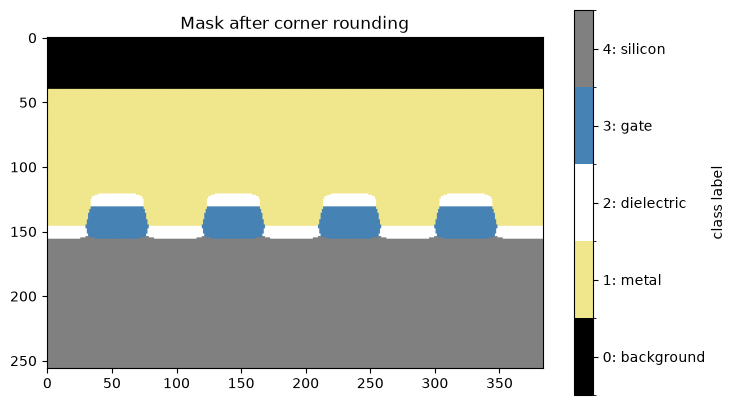

In [55]:
sigma = rng.uniform(*CORNER_BLUR_SIGMA_RANGE)
rounded_mask = round_corners(test_mask, N_CLASSES, blur_sigma=sigma)

print(f"Used blur_sigma={sigma:.2f}")

plt.figure(figsize=(8,5))
im = plt.imshow(rounded_mask, cmap=cmap, norm=norm)
plt.title("Mask after corner rounding")
cbar = plt.colorbar(im, ticks=range(N_CLASSES))
cbar.set_label("class label")
cbar.ax.set_yticklabels(['0: background', '1: metal', '2: dielectric', '3: gate', '4: silicon'])
plt.show()

In [65]:
# now we will turn this colorful image into a black and white image as given by
#real life SEM images

def render_sem_style(mask, rng, n_classes):
    """
    Converts an integer label mask into a noisy, SEM-like grayscale image.
    Label mapping: 0=background, 1=metal, 2=dielectric, 3=gate, 4=silicon
    """

    #assigning random grey color to different materials
    gray_map = {
        0: rng.uniform(15,35), # background - dark
        1: rng.uniform(150,190), #metal - mid_bright, gets grain texture added
        2: rng.uniform(220,250), #dielectric-brightest
        3: rng.uniform(130,160), #gate polysilicon
        4: rng.uniform(90,120), #silicon substrate
    }

    img = np.zeros(mask.shape, dtype=np.float32)
    for k,v in gray_map.items():
        img[mask==k] = v

        #1. Metal grain texture (only within metal region)
    metal_region = (mask==1)
    grain = rng.normal(0,18,mask.shape)
    grain=cv2.GaussianBlur(grain,(0,0),sigmaX=2.5)
    img[metal_region] += grain[metal_region]

        #2. Edge blur/beam spread (SEM edges are never perfectly sharp)
    img = cv2.GaussianBlur(img, (3,3), sigmaX=rng.uniform(0.6,1.4))

        #3. Background brightness gradient (uneven illumination)
    gx = np.linspace(rng.uniform(-10,10), rng.uniform(-10,10), img.shape[1])
    gy = np.linspace(rng.uniform(-8,8), rng.uniform(-8,8), img.shape[0])
    img += gx[None, :] + gy[:, None]

        #4. Gaussian sensor noise
    img += rng.normal(0, rng.uniform(6,14), img.shape)

        #5. sparse speckle (sall and pepper style)
    spec = rng.random(img.shape) <0.008
    img[spec] = rng.uniform(0,255, spec.sum())

    return np.clip(img, 0, 255).astype(np.uint8)

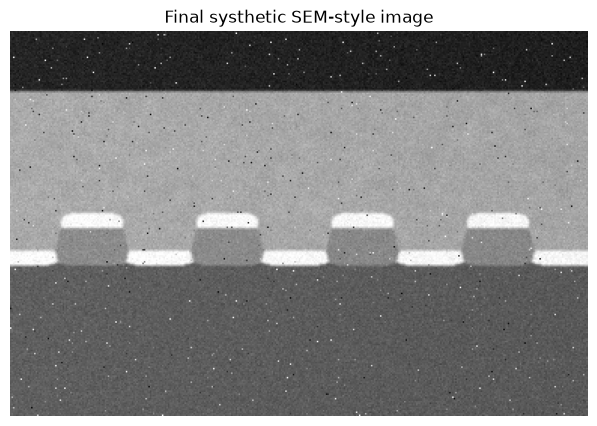

In [66]:
# seeing the newly type created image

sem_img = render_sem_style(rounded_mask, rng, N_CLASSES)

plt.figure(figsize=(8,5))
plt.imshow(sem_img, cmap='grey')
plt.title("Final systhetic SEM-style image")
plt.axis('off')
plt.show()


In [61]:
print("Unique classes in mask:", np.unique(rounded_mask, return_counts=True))

Unique classes in mask: (array([0, 1, 2, 3, 4], dtype=uint8), array([15360, 36460,  3464,  4508, 38512]))


In [62]:
print("img min/max:", sem_img.min(), sem_img.max())
print("Value at a background pixel (row 10):", sem_img[10, 10])
print("Value at a silicon pixel (row 200):", sem_img[200, 10])
print("Value at a metal pixel (row 60):", sem_img[60, 10])

img min/max: 0 254
Value at a background pixel (row 10): 39
Value at a silicon pixel (row 200): 0
Value at a metal pixel (row 60): 0


In [63]:
#### was stuck in an error, there was a indentation error in for loop which led to all black
#images
import inspect
print(inspect.getsource(render_sem_style))

def render_sem_style(mask, rng, n_classes):
    """
    Converts an integer label mask into a noisy, SEM-like grayscale image.
    Label mapping: 0=background, 1=metal, 2=dielectric, 3=gate, 4=silicon
    """

    #assigning random grey color to different materials
    gray_map = {
        0: rng.uniform(15,35), # background - dark
        1: rng.uniform(150,190), #metal - mid_bright, gets grain texture added
        2: rng.uniform(220,250), #dielectric-brightest
        3: rng.uniform(130,160), #gate polysilicon
        4: rng.uniform(90,120), #silicon substrate
    }

    img = np.zeros(mask.shape, dtype=np.float32)
    for k,v in gray_map.items():
        img[mask==k] = v

        #1. Metal grain texture (only within metal region)
        metal_region = (mask==1)
        grain = rng.normal(0,18,mask.shape)
        grain=cv2.GaussianBlur(grain,(0,0),sigmaX=2.5)
        img[metal_region] += grain[metal_region]

        #2. Edge blur/beam spread (SEM edges are never perfectly sharp)
  

In [67]:
#### now compiling all these steps in a loop, to generate 300 test images and save them

import os

DATA_DIR = "data"
IMG_DIR = os.path.join(DATA_DIR, "images")
MASK_DIR = os.path.join(DATA_DIR, "masks")

os.makedirs(IMG_DIR, exist_ok=True)
os.makedirs(MASK_DIR, exist_ok=True)

N_IMAGES = 300  # total dataset size

rows = []  # will hold ground-truth CD values for the CSV

for i in range(N_IMAGES):
    # randomize this image's structural parameters
    gate_width = int(rng.integers(*GATE_WIDTH_RANGE))
    gate_pitch = gate_width + int(rng.integers(*GATE_PITCH_EXTRA_RANGE))
    gate_height = int(rng.integers(*GATE_HEIGHT_RANGE))
    dielectric_thickness = int(rng.integers(*DIELECTRIC_THICKNESS_RANGE))
    metal_top_row = int(rng.integers(*METAL_TOP_ROW_RANGE))
    corner_sigma = rng.uniform(*CORNER_BLUR_SIGMA_RANGE)

    # build clean mask -> round corners -> render as noisy SEM image
    raw_mask = make_layered_pattern(
        rng, gate_width, gate_pitch, gate_height,
        dielectric_thickness, metal_top_row
    )
    final_mask = round_corners(raw_mask, N_CLASSES, blur_sigma=corner_sigma)
    sem_img = render_sem_style(final_mask, rng, N_CLASSES)

    # save both
    fname = f"sem_{i:04d}.png"
    cv2.imwrite(os.path.join(IMG_DIR, fname), sem_img)
    cv2.imwrite(os.path.join(MASK_DIR, fname), final_mask)  # raw integer labels 0-4

    # log ground truth
    rows.append([fname, gate_width, gate_pitch, gate_height,
                 dielectric_thickness, metal_top_row, round(corner_sigma, 3)])

# write ground truth CSV
csv_path = os.path.join(DATA_DIR, "ground_truth.csv")
with open(csv_path, "w", newline="") as f:
    writer = csv.writer(f)
    writer.writerow(["filename", "gate_width_px", "gate_pitch_px", "gate_height_px",
                      "dielectric_thickness_px", "metal_top_row_px", "corner_blur_sigma"])
    writer.writerows(rows)

print(f"Generated {N_IMAGES} images.")
print(f"Images: {IMG_DIR}")
print(f"Masks:  {MASK_DIR}")
print(f"Ground truth CSV: {csv_path}")

Generated 300 images.
Images: data/images
Masks:  data/masks
Ground truth CSV: data/ground_truth.csv


In [68]:
# sanity check, viewing some samples

import pandas as pd

# check the CSV
df = pd.read_csv(os.path.join(DATA_DIR, "ground_truth.csv"))
print(f"Total rows: {len(df)}")
df.head()

Total rows: 300


,filename,gate_width_px,gate_pitch_px,gate_height_px,dielectric_thickness_px,metal_top_row_px,corner_blur_sigma
0,sem_0000.png,38,100,27,11,48,3.877
1,sem_0001.png,44,82,27,7,41,4.347
2,sem_0002.png,30,96,19,8,37,3.885
3,sem_0003.png,51,105,20,7,47,4.807
4,sem_0004.png,36,94,26,13,43,4.331


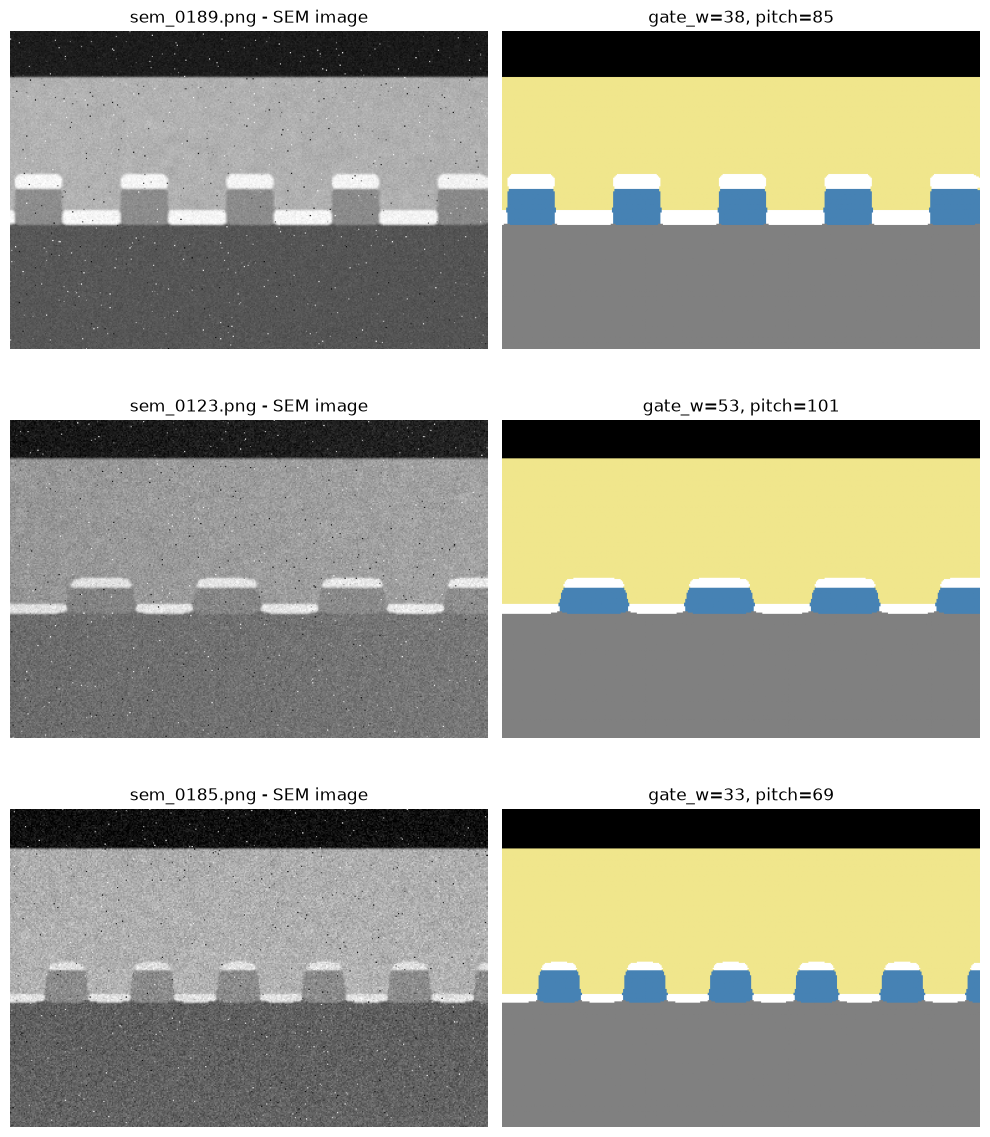

Unique values in this mask file: [0 1 2 3 4]


In [69]:
# reload a few random images + masks from disk and display
sample_rows = df.sample(3, random_state=1)

fig, axes = plt.subplots(3, 2, figsize=(10, 12))

for i, (_, row) in enumerate(sample_rows.iterrows()):
    fname = row["filename"]
    img = cv2.imread(os.path.join(IMG_DIR, fname), cv2.IMREAD_GRAYSCALE)
    mask = cv2.imread(os.path.join(MASK_DIR, fname), cv2.IMREAD_GRAYSCALE)

    axes[i, 0].imshow(img, cmap='gray')
    axes[i, 0].set_title(f"{fname} - SEM image")
    axes[i, 0].axis('off')

    axes[i, 1].imshow(mask, cmap=cmap, norm=norm)
    axes[i, 1].set_title(f"gate_w={row['gate_width_px']}, pitch={row['gate_pitch_px']}")
    axes[i, 1].axis('off')

plt.tight_layout()
plt.show()

# confirm mask files actually contain raw class labels 0-4, not colors
print("Unique values in this mask file:", np.unique(mask))